In [76]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

# Load files

In [77]:
# POT taken from preselection stage

lambda_pot = 1.428596135616784e+23
aurora_pot = 5.401777280854836e+20

In [78]:
#lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/lambdaFransOutput.root"
lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/newChi2LambdaFransOutput.root"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/devFransOutput.root"

frans_tdir = "FRANSProducer/fransTree"

In [79]:
lambda_tree = uproot.open(lambda_file)[frans_tdir]
aurora_tree = uproot.open(aurora_file)[frans_tdir]

Task was destroyed but it is pending!
task: <Task pending name='Task-489' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at /home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/ipykernel/utils.py:76> wait_for=<Task pending name='Task-490' coro=<_async_in_context.<locals>.preserve_context() running at /home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/ipykernel/utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/uproot/source/chunk.py:446: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  self.wait(insist=stop)
Task was destroyed but it is pending!
task: <Task pending name='Task-490' coro=<_async_in_context.<locals>.preserve_context() running at /home/sye

In [80]:
max_entry = None
indices =['run_id', 'subrun_id', 'event_id', 'slice_id']

lambda_df = pd.DataFrame(lambda_tree.arrays(branches.frans, library="np", entry_stop=max_entry))
aurora_df = pd.DataFrame(aurora_tree.arrays(branches.frans, library="np", entry_stop=max_entry))

lambda_df.set_index(indices, inplace=True)
aurora_df.set_index(indices, inplace=True)

In [81]:
pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_df.n_lambda > 0) | (aurora_df.n_sigma0 > 0)

lambda_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_df['scale'] = aurora_scale
aurora_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

In [82]:
# Cosmic scaling

'''
hyp_rate = len(aurora_sgnl_mask.groupby(['event_id', 'run_id', 'subrun_id']).any()) / len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id']))

events_i_have = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id']))
total_events = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) / hyp_rate + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) * (1-hyp_rate)/hyp_rate

aurora_cosmic_mask = (aurora_df.gen_index > 1)
lambda_cosmic_mask = (lambda_df.gen_index > 1)

#aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / aurora_pot * hyp_cosmic_scaling
#lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * hyp_cosmic_scaling

cosmic_scaling = pot_3y / (lambda_pot + aurora_pot) * total_events / events_i_have

aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scaling
lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scaling
'''

"\nhyp_rate = len(aurora_sgnl_mask.groupby(['event_id', 'run_id', 'subrun_id']).any()) / len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id']))\n\nevents_i_have = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id']))\ntotal_events = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) / hyp_rate + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) * (1-hyp_rate)/hyp_rate\n\naurora_cosmic_mask = (aurora_df.gen_index > 1)\nlambda_cosmic_mask = (lambda_df.gen_index > 1)\n\n#aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / aurora_pot * hyp_cosmic_scaling\n#lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * hyp_cosmic_scaling\n\ncosmic_scaling = pot_3y / (lambda_pot + aurora_pot) * total_events / events_i_have\n\naurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scalin

In [83]:
df = pd.concat([lambda_df, aurora_df])

# Michel tagging column

In [84]:
'''
df["michel_final_score"] = np.where(
    df["michel_score"] == -1,
    2,
    df["michel_score"]
)'''

df["michel_final_score"] = np.where(
    ~df["michel_vars_computed"],
    2,
    df["michel_score"]
)

# Preselection

In [86]:
cr_pre_mask = ((~df.pre_is_clear_cosmic) & 
               (df.pre_nu_score > 0.5) &
               (df.pre_bcfm_score > 0.04) &
               (df.pre_is_fiducial))

pre_df = df[cr_pre_mask]

# Selection

import importlib
import src

importlib.reload(src.driver)
importlib.reload(src.plotter)
importlib.reload(src.frans_branches)
importlib.reload(src.cuts)
from src.driver import AnalysisDriver
from src.frans_branches import branches
from src.cuts import CutConfig, create_cut

In [11]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [12]:
cuts_config = []

for cut_cfg in config['frans_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

In [87]:
driver = AnalysisDriver(df, cuts_config) # using df not to include preselection

driver = AnalysisDriver(pre_df, cuts_config) # pre_df include cosmic removal and FV

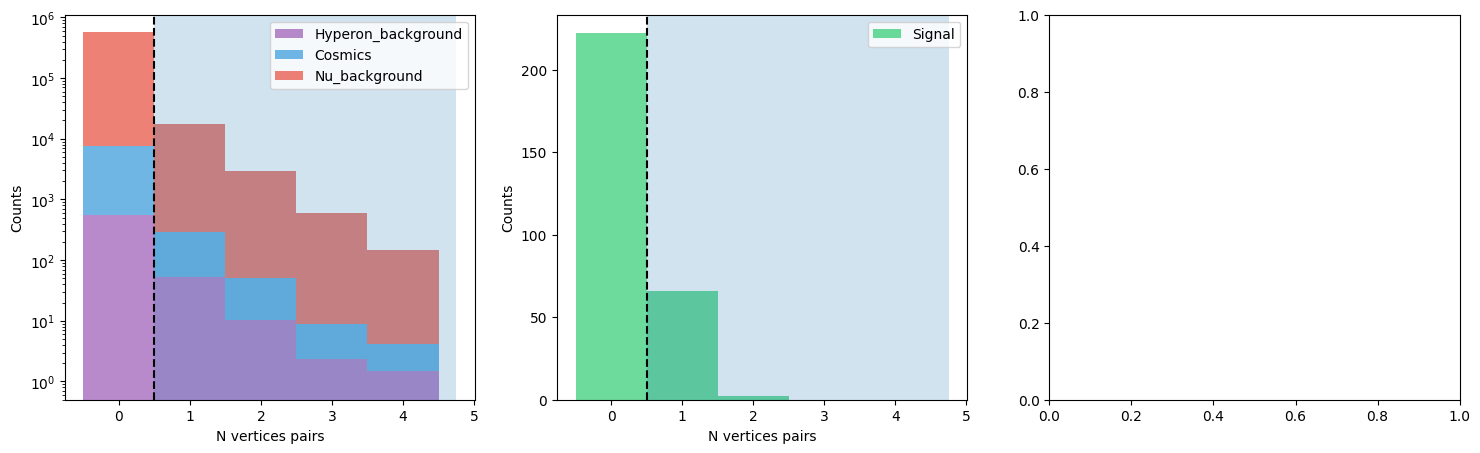

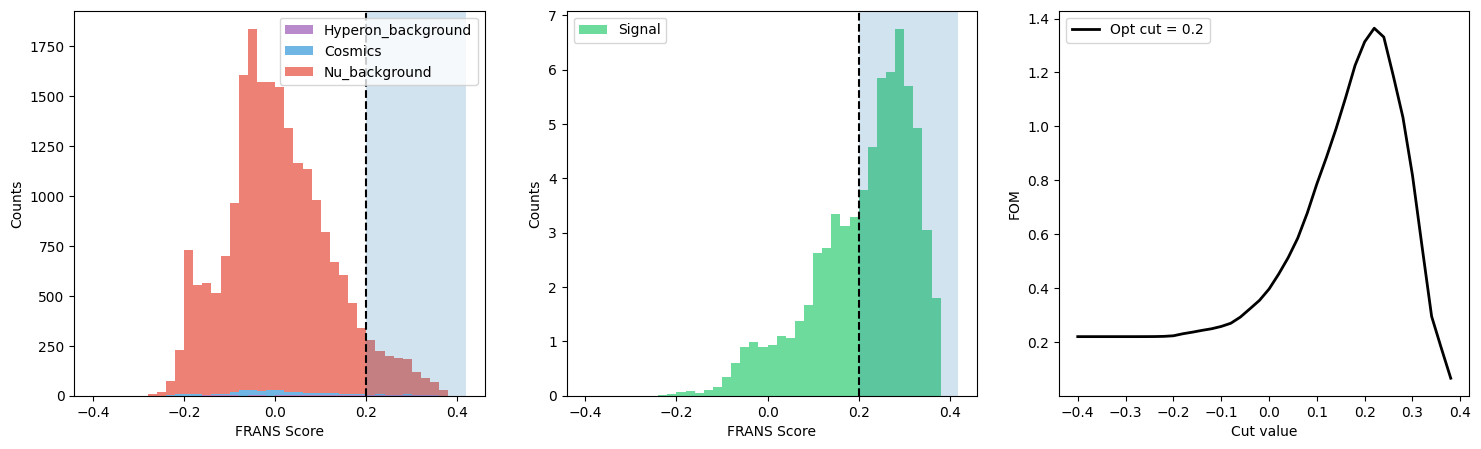

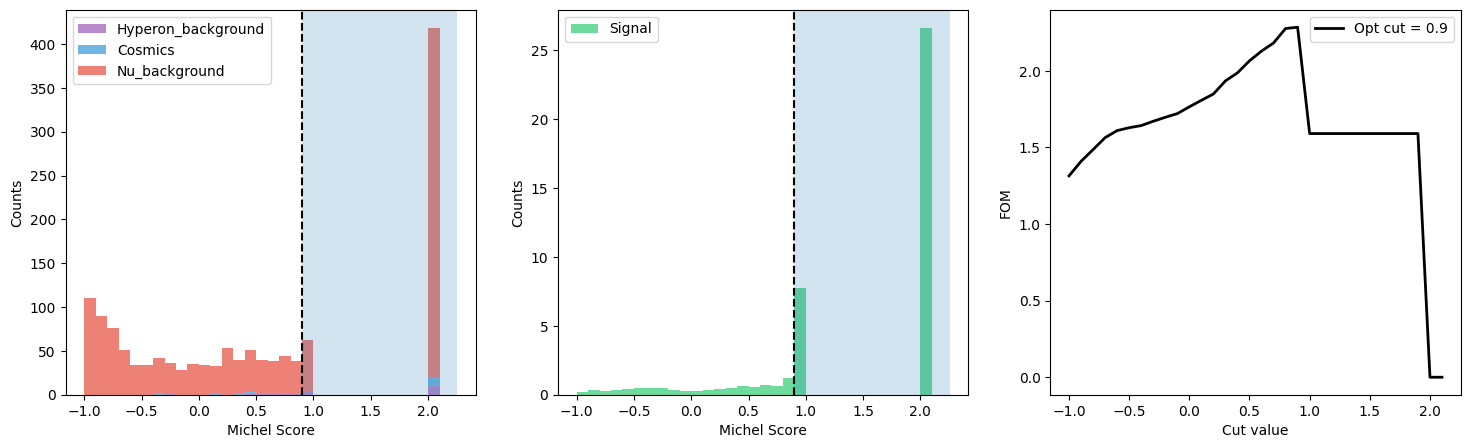

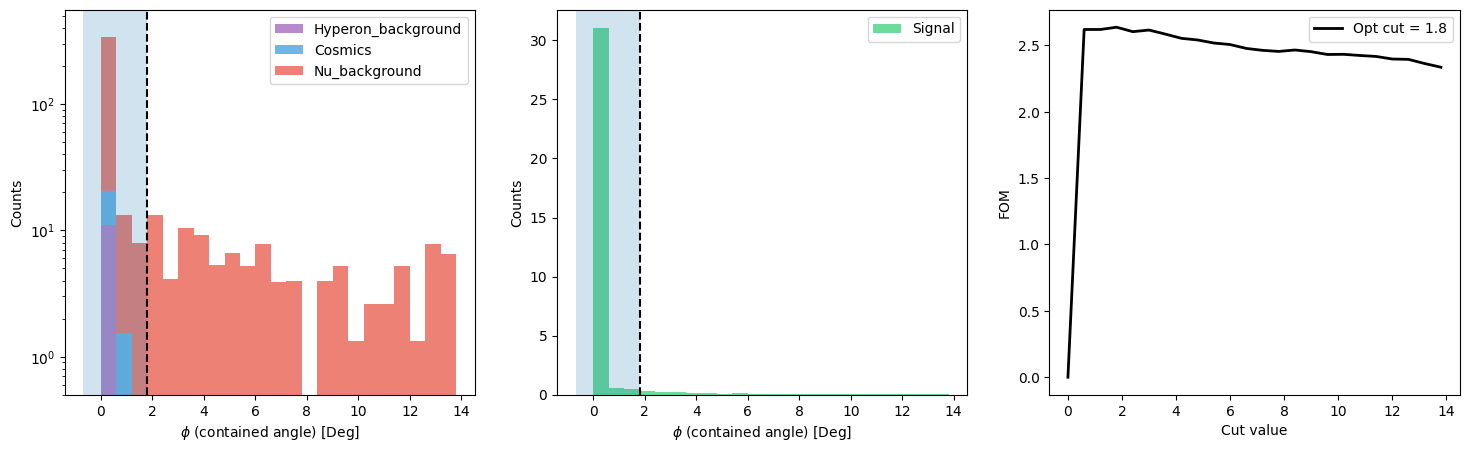

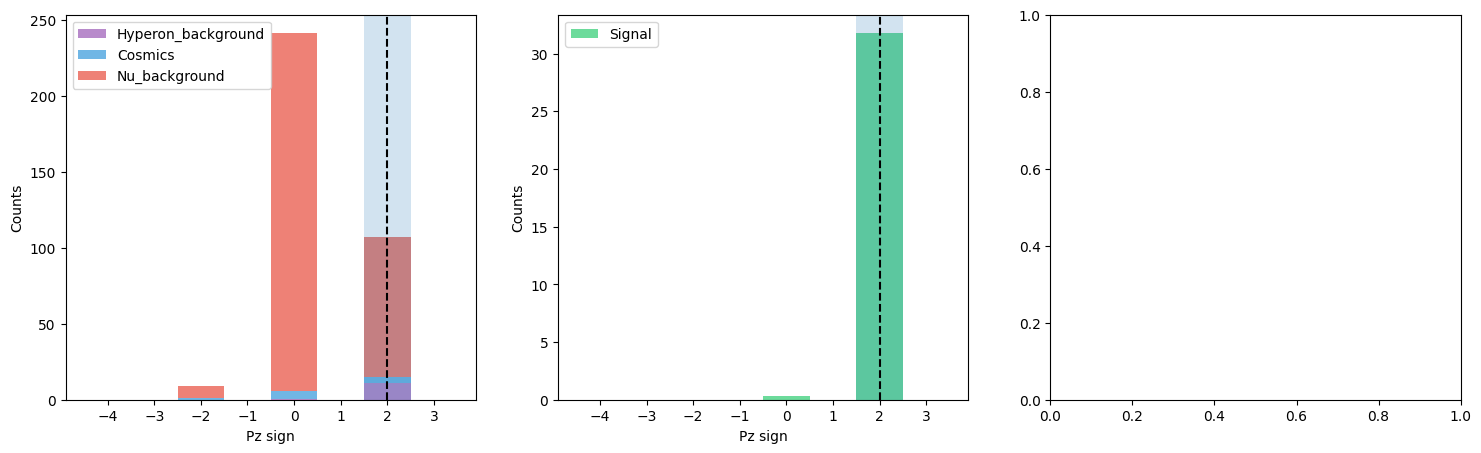

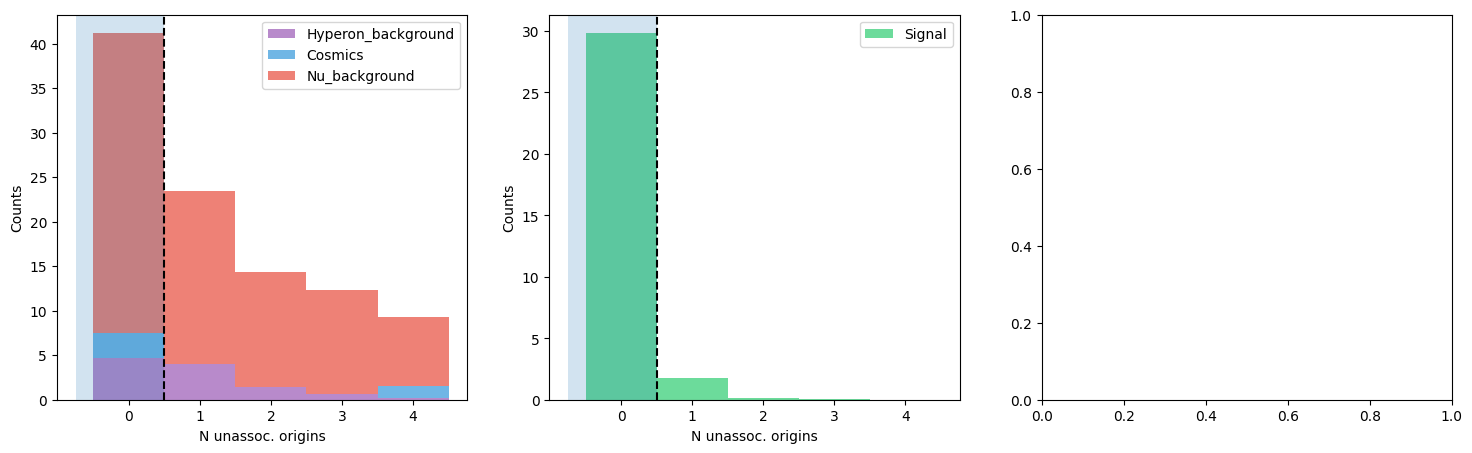

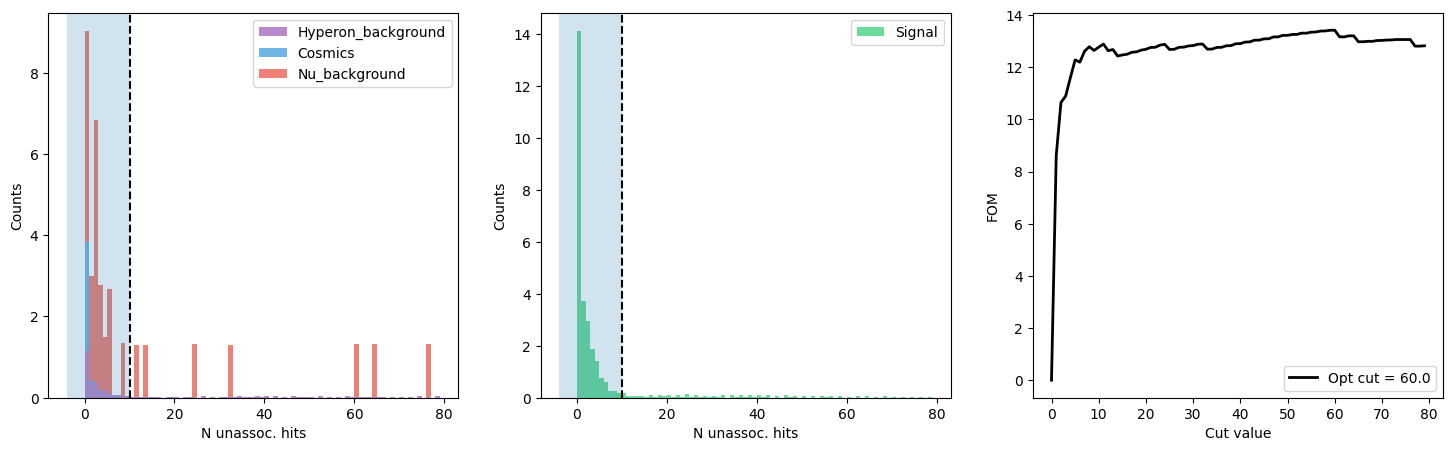

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,N vertices pairs,>= 1,68.8,66.7,293.9,2.1e+04,23.66,16.51,0.32,96.45,99.9185
1,FRANS Score,> 0.2,43.4,18.3,18.5,1.4e+03,62.99,10.40,3.03,93.51,99.9947
2,Michel Score,>= 0.9,34.3,12.8,10.7,457.4,79.14,8.23,6.66,65.32,99.9982
3,$\phi$ (contained angle) [Deg],< 1.8,32.1,11.4,10.7,335.6,93.45,7.69,8.22,25.62,99.9986
4,Pz sign,== 2,31.8,11.0,4.2,92.0,99.10,7.62,22.86,70.04,99.9996
5,N unassoc. origins,< 1,29.8,4.6,2.8,33.7,93.89,7.15,42.01,61.59,99.9998
6,N unassoc. hits,< 10,26.1,2.5,2.8,22.0,87.60,6.27,48.87,33.61,99.9999


In [88]:
driver.plot_cuts()
driver.get_cuts_performance(**config['initial_amounts'])

In [89]:
final_df = driver.get_final_df()

In [90]:
len(final_df.groupby(level=['run_id', 'subrun_id', 'event_id']))

5928

In [91]:
final_group = final_df.groupby(level=['run_id', 'subrun_id', 'event_id'])

mask = (final_group.size() == 2)

mask[mask]

Series([], dtype: bool)

# Load FRANS PID tree

In [92]:
pid_tdir = "lambdaPidPandoraAna/CalorimetryTree"

lambda_pid_tree = uproot.open(lambda_file)[pid_tdir]
aurora_pid_tree = uproot.open(aurora_file)[pid_tdir]

In [93]:
lambda_pid_df = pd.DataFrame(lambda_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))
aurora_pid_df = pd.DataFrame(aurora_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))

In [94]:
pid_df = pd.concat([lambda_pid_df, aurora_pid_df])

In [95]:
pid_df.set_index(['RunID', 'SubRunID', 'EventID'], inplace=True)

In [96]:
final_df.index = final_df.index.droplevel(-1)
selected_indices = final_df.index

In [97]:
selected_indices= selected_indices[~selected_indices.isin([(1,446, 34)])]

In [98]:
pid_df = pid_df[pid_df.index.isin(selected_indices)]

In [99]:
cols = ['is_lambda_signal', 'scale', 'gen_index', 'n_hyperon']

pid_df[cols] = final_df.loc[selected_indices, cols].values

In [100]:
pid_df['pid_cut'] = (pid_df.NTracksHI >=1) & (pid_df.NTracksLI >=1)

In [101]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [102]:
pid_cuts_config = []

for cut_cfg in config['pid_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    pid_cuts_config.append(cfg)

In [103]:
pid_driver = AnalysisDriver(pid_df, pid_cuts_config)

/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7132: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)
/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7117: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  bins = np.histogram_bin_edges(


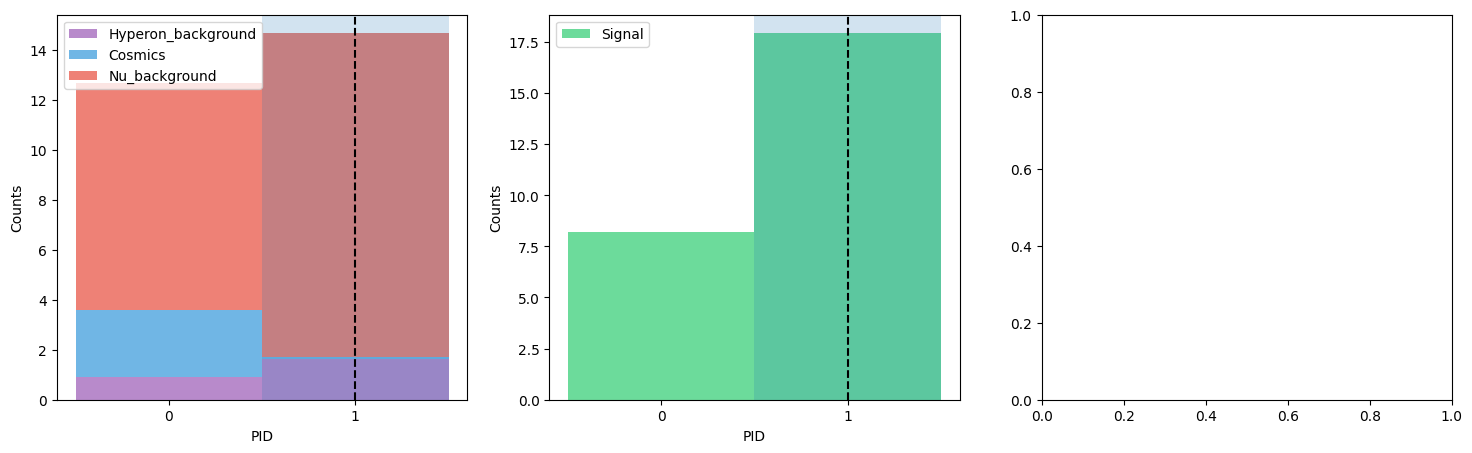

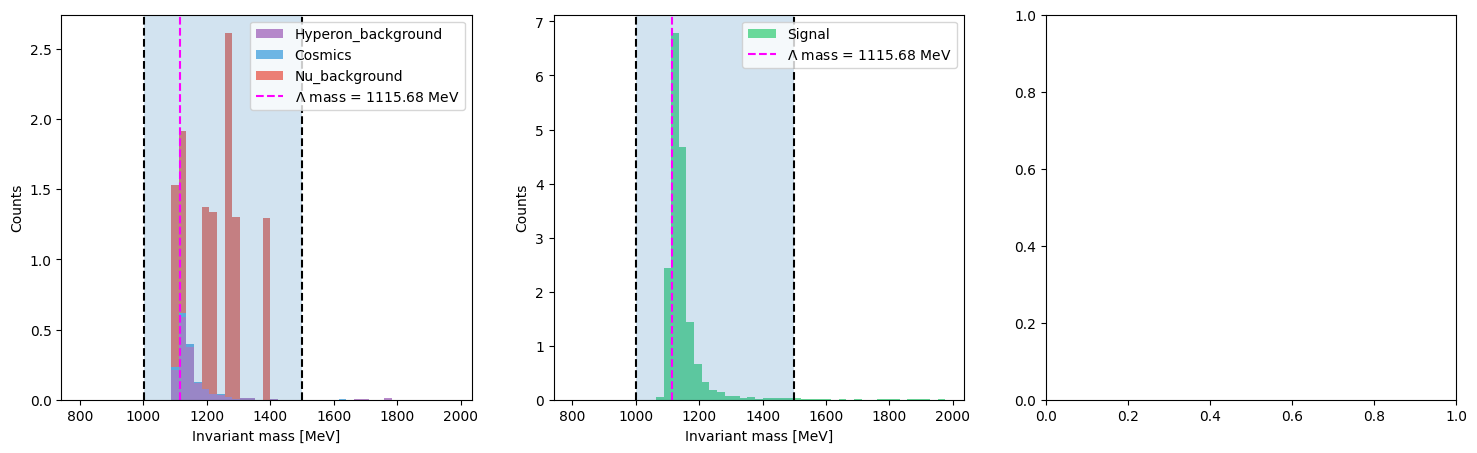

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,PID,== 1,17.9,1.6,0.1,13.0,68.65,4.30,55.00,46.33,99.9999
1,Invariant mass [MeV],"[1000, 1499]",17.1,1.5,0.1,10.4,95.16,4.09,58.84,18.63,100.0000


In [104]:
pid_driver.plot_cuts()
pid_driver.get_cuts_performance(**config['initial_amounts'])

# Signal lost in preselection

In [32]:
final_pid_df = pid_driver.get_final_df()

In [36]:
selected_lambda_indices = final_pid_df[final_pid_df.is_lambda_signal].index

In [39]:
mask = final_df.index.isin(selected_lambda_indices)
selected_lambda_df = final_df[mask]

In [44]:
no_preselected_lambda_df = selected_lambda_df[~selected_lambda_df.pre_pass]

In [65]:
n = len(no_preselected_lambda_df)
n

851

In [66]:
sum(no_preselected_lambda_df.pre_max_gap < 0.01) / n * 100 # salvable contando las showers en el gap

55.346650998824906

<Axes: >

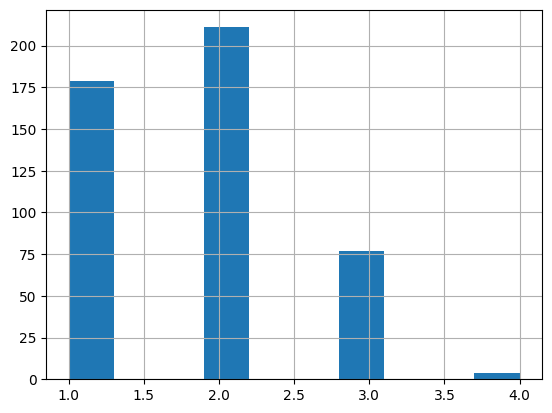

In [75]:
no_preselected_lambda_df[(no_preselected_lambda_df.pre_max_gap < 0.01)].pre_n_prim_trks.hist() # encuentro las pfps en la slice

<Axes: >

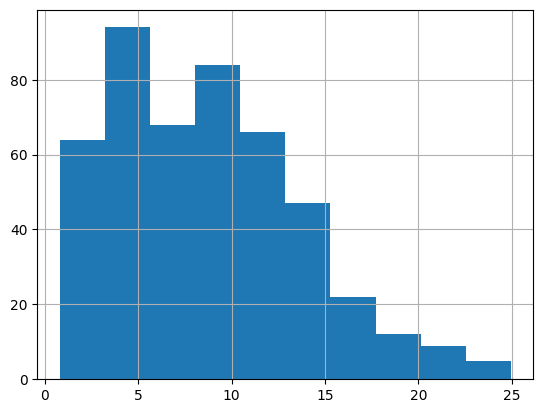

In [71]:
no_preselected_lambda_df[(no_preselected_lambda_df.pre_max_gap < 0.01)].true_gap.hist() # son true gaps grandes 

In [67]:
mask = (no_preselected_lambda_df.pre_max_gap > 1)

sum(no_preselected_lambda_df[mask].pre_bcfm_score < 0.04) / n * 100

17.508813160987074

In [68]:
mask = ((no_preselected_lambda_df.pre_max_gap > 1) & 
        (no_preselected_lambda_df.pre_bcfm_score > 0.04))

sum(no_preselected_lambda_df[mask].pre_n_trks_exit > 1) / n * 100

23.149236192714454

In [69]:
preselection_cuts = ['pre_is_clear_cosmic',
 'pre_nu_score',
 'pre_bcfm_score',
 'pre_is_fiducial',
 'pre_n_prim_pfps',
 'pre_n_prim_trks',
 'pre_n_prim_shwrs',
 'pre_n_trks_exit',
 'pre_max_gap',
 'true_gap',                     
 'pre_pass',]

no_preselected_lambda_df.loc[
    (no_preselected_lambda_df.pre_max_gap>1), 
    preselection_cuts].head(50)

pre_is_clear_cosmic  pre_nu_score  pre_bcfm_score  \
run_id subrun_id event_id                                                      
1      2311      45                      False      0.685454   -1.000000e+00   
       2319      36                      False      0.654189    1.263499e-01   
       2323      21                      False      0.667639    1.478716e-01   
                 28                      False      0.647401    6.249052e-01   
       2329      63                      False      0.669845    1.050120e-01   
       2332      55                      False      0.445441    8.573054e-02   
       1943      21                      False      0.633843    1.000000e-06   
       2347      32                      False      0.693626    1.000000e-06   
       2351      70                      False      0.697344    5.432079e-01   
       2360      50                      False      0.676583    5.381224e-01   
       1140      14                      False      0.660374    1.000000e-06   
       2419      56                      False      0.491237    1.094280e-01   
       2421      24                      False      0.683259    2.466623e-01   
       2439      52                      False      0.684999    9.994680e-02   
       2452      50                      False      0.537636    8.755819e-01   
       2457      38                      False      0.638665    7.808954e-02   
       2474      42                      False      0.699498    1.000000e-06   
       2476      35                      False      0.547922    9.311499e-02   
                 50                      False      0.679352    8.532646e-02   
       1149      64                      False      0.705436    1.083016e-01   
       2506      3                       False      0.655937    1.000000e-06   
       2532      36                      False      0.622176    1.000000e-06   
       255       46                      False      0.728428    1.000000e-06   
       2574      4                       False      0.714961    1.000000e-06   
       2579      70                      False      0.620692    1.189028e+00   
       2578      8                       False      0.705996    2.241617e-01   
       2586      52                      False      0.671378    1.000000e-06   
       1967      19                      False      0.569876    1.109409e-01   
       1968      74                      False      0.653748    1.000000e-06   
       2595      60                      False      0.609524    2.609267e-01   
       1161      50                      False      0.703518    8.330442e-01   
       262       57                      False      0.680446    7.672498e-02   
                 75                      False      0.486869    1.297526e-01   
       2625      53                      False      0.676491    1.000000e-06   
       1163      26                      False      0.602333    3.537266e-01   
       2637      72                      False      0.647760    1.000000e-06   
       2651      3                       False      0.495413    1.118365e-01   
       2652      16                      False      0.710259    1.000000e-06   
       2666      16                      False      0.625223    2.262017e-01   
       1975      23                      False      0.717996    1.000000e-06   
       2677      11                      False      0.598593    6.603411e-02   
       117       53                      False      0.641685    8.692128e-01   
       2720      48                      False      0.634372    2.539508e-01   
       1173      43                      False      0.707410    1.000000e-06   
       2732      23                      False      0.657461    1.000000e-06   
       2752      53                      False      0.675578    1.000000e-06   
       2754      68                      False      0.636351    9.748454e-02   
       2769      27                      False      0.475233    1.103218e-01   
       277       22        